# ML Example: ResNet34 Segmentation Inference
This notebook demonstrates inference with the extracted fastai model utilities.

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('/home/axt807/ivory_project/github_repo/src').resolve()))
from fastai.data.transforms import get_image_files
from ivory_repo.ml import load_model, new_show_predictions

Loading the dataset paths:

In [6]:
# Update these paths for your environment
path = Path("/mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/")
path_lbl = path / "binary_masks_new"
test_path_ivory = Path("/mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/ivory")
test_path_bone = Path("/mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/bone")
outpath = Path("/mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/inference")
outpath.mkdir(parents=True, exist_ok=True)

Loading the resnet model and plotting some sample predictions: 

{'ivory_frac': [0.9003928922225198,
  0.6479308214947499,
  0.9881520778072502,
  0.720369231898553,
  0.963859614237423],
 'avg_pred': [0.6676202450862037,
  0.22920563629598767,
  0.8364315667181331,
  0.40599398092890915,
  0.8633009023296979],
 'class': ['ivory', 'uncertain', 'ivory', 'ivory', 'ivory']}

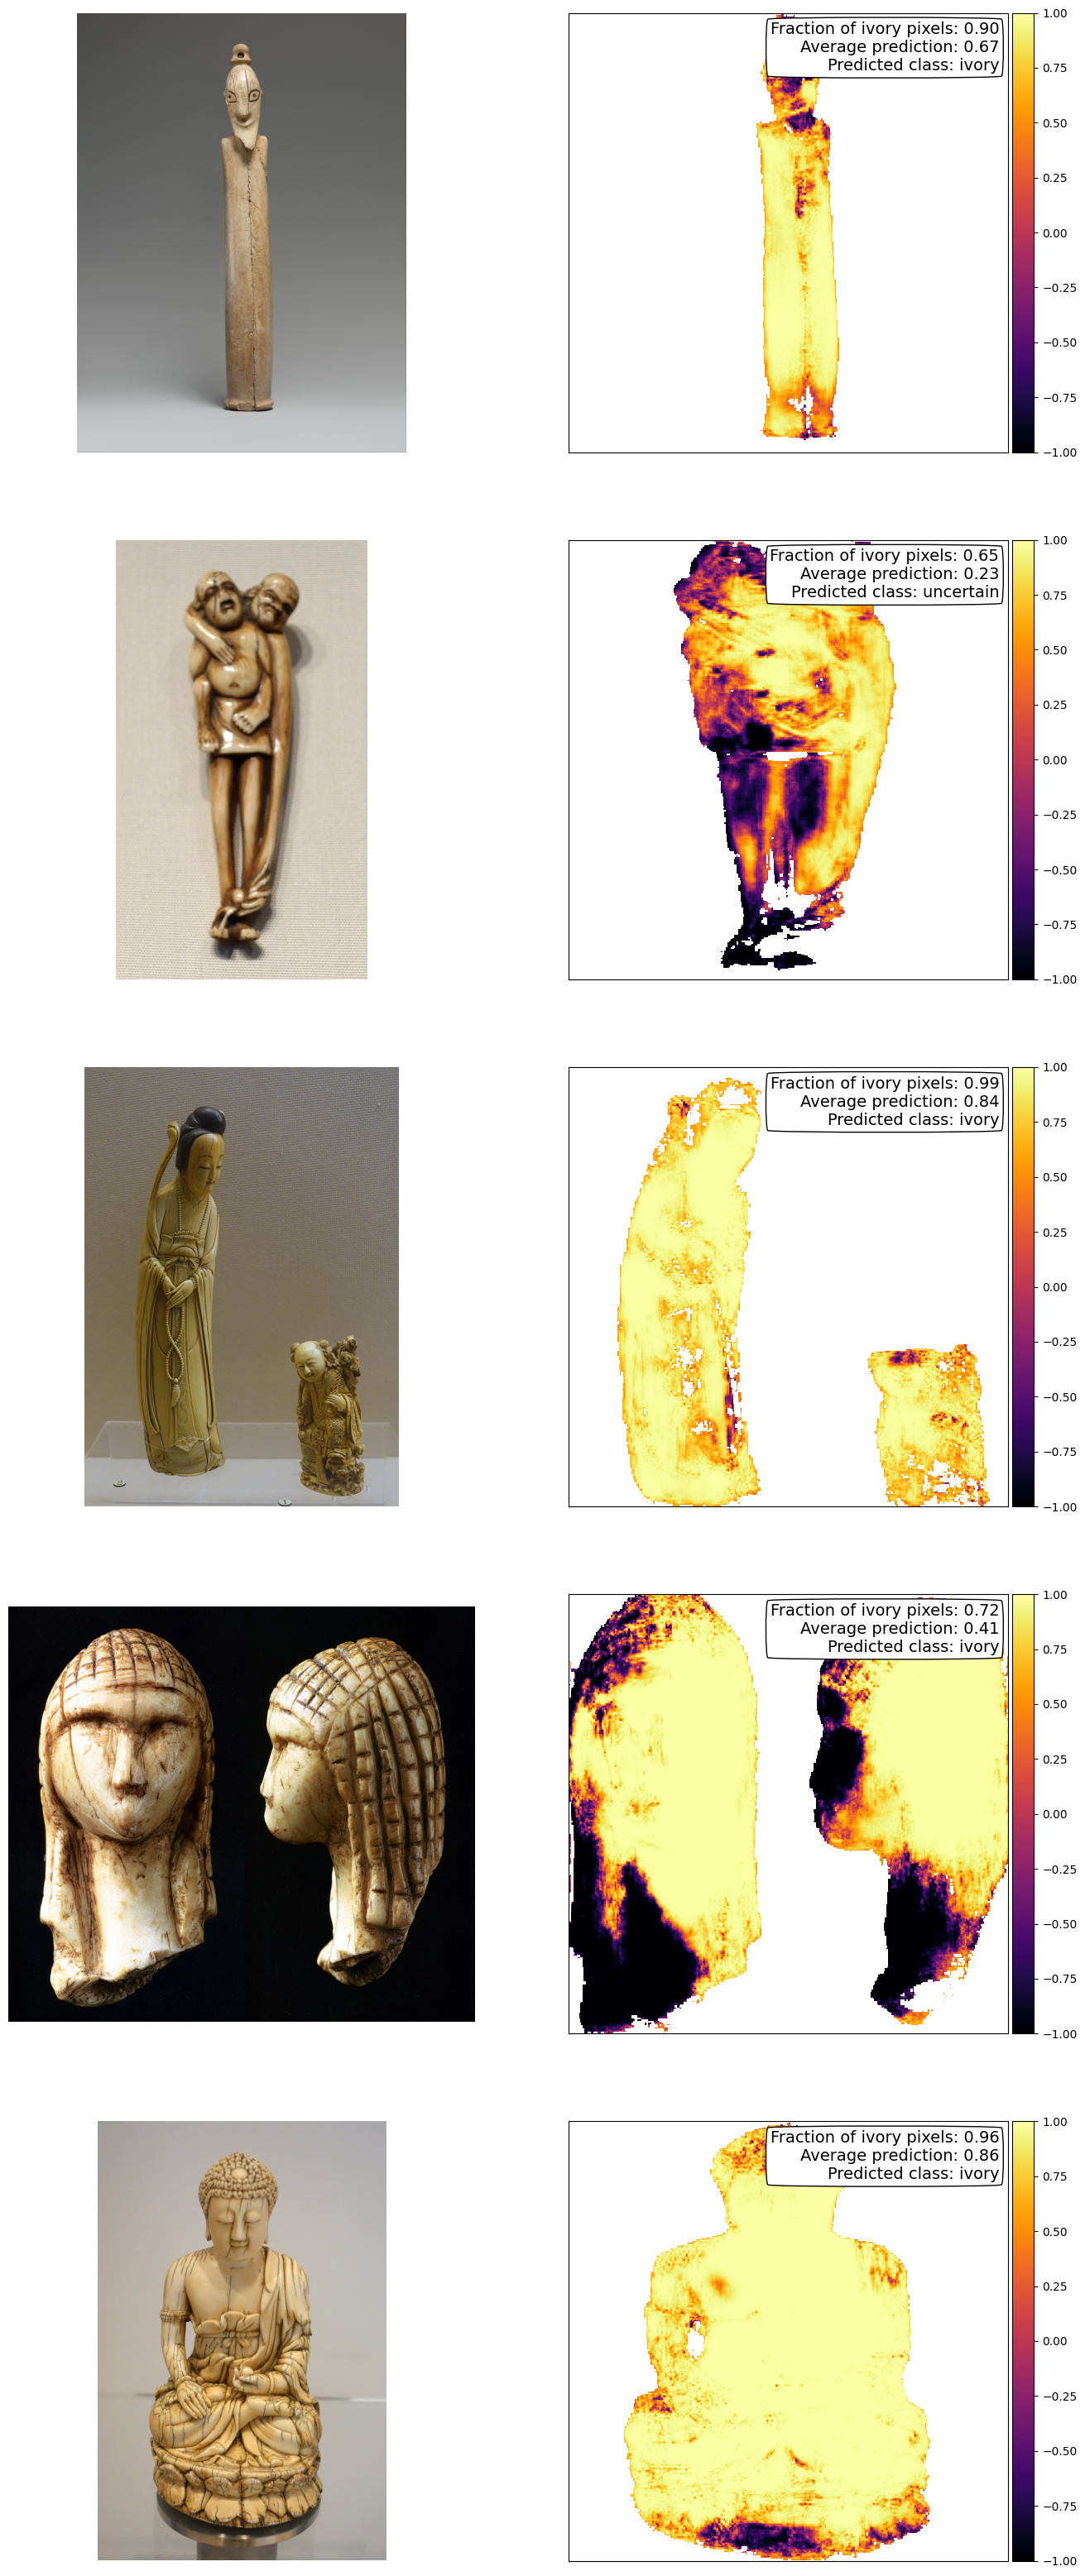

In [ ]:
learn = load_model(model_index=3, train_path=path, path_lbl=path_lbl)
fnames = get_image_files(test_path_ivory)
dl = learn.dls.test_dl(fnames)
preds = learn.get_preds(dl=dl)
ivory_pred = new_show_predictions(test_path_ivory, preds, npics=5, outname=str(outpath / "Ivory"))
ivory_pred

/home/axt807/miniconda3/envs/ivory_project/lib/python3.10/site-packages/fastai/metrics.py:375: RuntimeWarning: Mean of empty slice
  return np.nanmean(binary_dice_scores)


{'ivory_frac': [0.04950771687067589,
  0.49577980677354283,
  0.9799350277087713,
  0.13436099267519405,
  0.8806833114323259],
 'avg_pred': [-0.8581358072217583,
  -0.04037805443327257,
  0.7937916687252091,
  -0.6947858922360268,
  0.5514332812969694],
 'class': ['bone', 'uncertain', 'ivory', 'bone', 'ivory']}

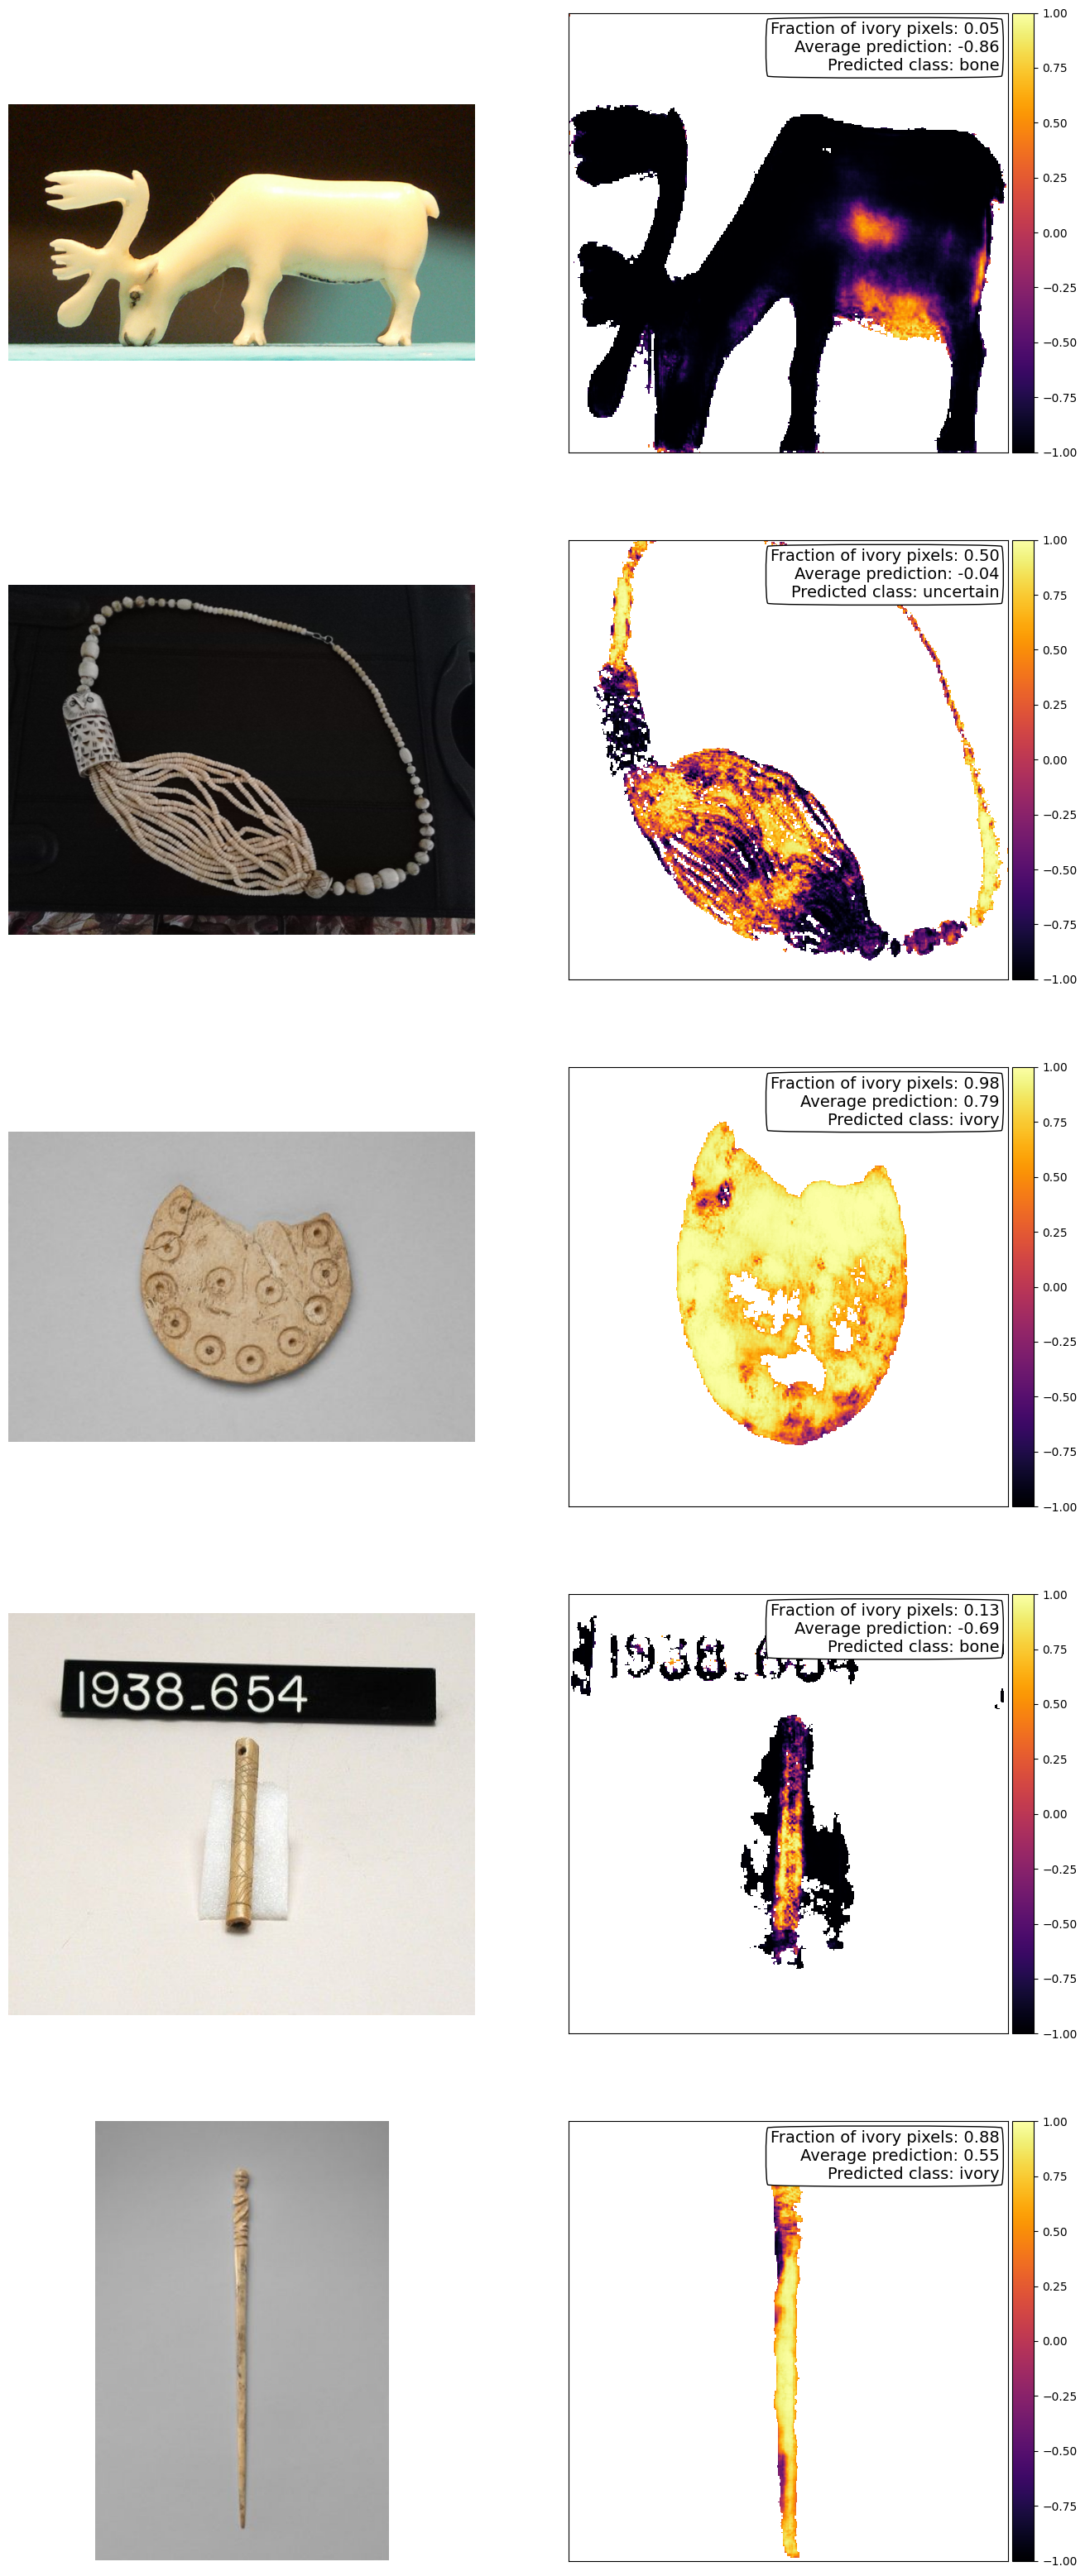

In [7]:
learn = load_model(model_index=3, train_path=path, path_lbl=path_lbl)
fnames = get_image_files(test_path_bone)
dl = learn.dls.test_dl(fnames)
preds = learn.get_preds(dl=dl)
bone_pred = new_show_predictions(test_path_bone, preds, npics=5, outname=str(outpath / "Bone"))
bone_pred